# Multivariate functional PCA and airfoil clustering

**Question.** Does organizing airfoils by complete $C_D(\alpha,Re)$ and $C_L(\alpha,Re)$ surfaces produce more aerodynamically homogeneous groups than organizing them by camber parameters?

**Hypothesis to test.** Balanced functional scores retain operating-domain variation lost in coefficient averages and in camber-only geometry. Evidence consists of held-out reconstruction, lower full-field within-cluster error at matched $k$, and reproducible partitions under subsampling. These are descriptive surrogate-model results, not evidence of physical classes or CFD validation.

The experiment compares **K-means, Ward linkage, and full-covariance Gaussian mixtures** in five representations: 99%-variance MFPCA, two functional PCs, domain means, standardized camber $(m,p)$, and standardized full geometry $(m,p,t)$. Full-field K-means supplies an unreduced reference. The fixed primary comparison uses $k=4$; the complete $k=2,\ldots,8$ sweep prevents a conclusion from depending on that choice. No known cluster labels exist; agreement with camber is a comparison, not accuracy.

Run all cells from the repository root or `notebooks/`. Install `requirements.txt` and `requirements-analysis.txt` in a compatible Python environment. The first run generates a provenance-keyed numeric cache; subsequent runs reuse it. All result tables, assignments, fitted modes, and figure PDFs/PNGs are saved. Reusable calculations and plots are in `utils/functional_clustering.py`.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import platform
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if not (ROOT / "utils/generate_airfoil_database.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "utils/generate_airfoil_database.py").exists(), "Run from root or notebooks/."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from utils.generate_airfoil_database import generate_airfoil_database, generate_airfoil_outputs
from utils.functional_clustering import (
    FunctionalPCA, representations, fit_clusters, field_metrics, reconstruction_metrics,
    plot_reduction, plot_cluster_sweep, plot_partition_maps, plot_cluster_fields,
)

plt.style.use(ROOT / "utils/academic.mplstyle")
# Avoid oversubscribing BLAS on these small sample-space decompositions.
thread_limits = threadpool_limits(limits=1)
SEED = 42
PRIMARY_K = 4
K_VALUES = range(2, 9)
VARIANCE_FRACTION = 0.99
STABILITY_REPEATS = 10
RESULTS = ROOT / "data/multivariate_pca_clustering"
FIGURES = ROOT / "figures/multivariate_pca_clustering"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
versions = {name: metadata.version(name) for name in
            ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn", "AeroSandbox", "NeuralFoil"]}
display(pd.Series(versions, name="version").to_frame())

,version
numpy,2.5.3
scipy,1.18.1
pandas,3.0.5
matplotlib,3.11.1
scikit-learn,1.7.2
AeroSandbox,4.2.10
NeuralFoil,0.3.3


## 1. Population, operating domain, and data checks

The generator stores `(maximum camber, camber position, thickness)` as chord fractions. Thus $(0.02,0.4,0.12)$ is NACA 2412. The family has $m=0,2,4,6,8\%$, $p=20,40,60,80\%$, and $t=6,8,\ldots,24\%$ of chord. Symmetric airfoils appear once per thickness, with the convention $p=0$ (undefined physically). There are 170 unique airfoils. The previous notebook incorrectly extracted position/thickness as camber variables; those maps and their unsupported interpretation are superseded by this explicit parameterization.

We retain the requested 50-by-50 grid on $\alpha\in[-15,15]$ degrees and $Re\in[10^6,2\times10^6]$, Mach 0, NeuralFoil `xxsmall`. Legacy `.npy` files lack grid/model metadata and are left untouched. This experiment caches numeric arrays with explicit axes, coefficient order, geometry, model settings, source hash, and software versions. Nonfinite fields or nonpositive drag stop the experiment; no failed point is silently removed.

In [2]:
airfoils = generate_airfoil_database()
geometry = np.asarray(airfoils.airfoil.tolist(), dtype=float)
alphas = np.linspace(-15, 15, 50)
reynolds = np.linspace(1e6, 2e6, 50)
config = {
    "geometry": geometry.tolist(), "alphas": alphas.tolist(), "reynolds": reynolds.tolist(),
    "coefficients": ["CD", "CL"], "method": "neuralfoil", "model_size": "xxsmall", "mach": 0.0,
    "generator_sha256": hashlib.sha256((ROOT / "utils/generate_airfoil_database.py").read_bytes()).hexdigest(),
    "versions": {key: versions[key] for key in ["numpy", "AeroSandbox", "NeuralFoil"]},
}
config_json = json.dumps(config, sort_keys=True)
cache_key = hashlib.sha256(config_json.encode()).hexdigest()[:16]
cache_path = RESULTS / f"fields_{cache_key}.npz"
if cache_path.exists():
    with np.load(cache_path, allow_pickle=False) as cached:
        assert str(cached["config"]) == config_json
        fields = cached["fields"]
    print("Reused", cache_path.relative_to(ROOT))
else:
    aeros = generate_airfoil_outputs(airfoils, alphas, reynolds, method="neuralfoil",
                                     model_size=config["model_size"], mach=config["mach"])
    # Verify the generator's long-form ordering before any reshape.
    assert aeros.airfoil.tolist() == [g for g in airfoils.airfoil for _ in range(len(alphas) * len(reynolds))]
    np.testing.assert_array_equal(aeros.alpha, np.tile(np.repeat(alphas, len(reynolds)), len(airfoils)))
    np.testing.assert_array_equal(aeros.Re, np.tile(reynolds, len(airfoils) * len(alphas)))
    fields = aeros[["CD", "CL"]].to_numpy().reshape(len(airfoils), len(alphas), len(reynolds), 2)
    assert np.isfinite(fields).all() and np.all(fields[..., 0] > 0)
    np.savez_compressed(cache_path, fields=fields, geometry=geometry, alphas=alphas,
                        reynolds=reynolds, coefficients=np.array(["CD", "CL"]), config=config_json)
    print("Generated", cache_path.relative_to(ROOT))
assert fields.shape == (170, 50, 50, 2)
assert np.isfinite(fields).all() and np.all(fields[..., 0] > 0)
assert len(np.unique(geometry, axis=0)) == len(geometry)
parameters = pd.DataFrame(geometry, columns=["camber", "camber_position", "thickness"])
parameters.insert(0, "airfoil", [f"NACA{round(m*100)}{round(p*10)}{round(t*100):02d}" for m, p, t in geometry])
display(pd.DataFrame({"coefficient": ["CD", "CL"], "min": fields.min(axis=(0, 1, 2)),
                      "max": fields.max(axis=(0, 1, 2)), "missing": (~np.isfinite(fields)).sum(axis=(0, 1, 2))}))
print(f"{len(fields)} airfoils; {len(alphas)*len(reynolds)} operating points each")

Reused data/multivariate_pca_clustering/fields_f172ec2047e982df.npz


,coefficient,min,max,missing
0,CD,0.004922,0.288951,0
1,CL,-1.464631,2.043145,0


170 airfoils; 2500 operating points each


## 2. Functional metric and reduction

Let $w_{ab}$ be tensor-product trapezoidal weights normalized to sum to one, uniform in **linear** $\alpha$ and $Re$. For coefficient $j$, estimate $s_j^2=\sum_{ab}w_{ab}\operatorname{Var}_{i}(f_{iabj})$ from training airfoils. We diagonalize the centered matrix

$$X_{i,(abj)}=\sqrt{w_{ab}}\,[f_{iabj}-\bar f_{abj}]/s_j.$$

Its Euclidean distance is the discretized product-$L^2$ distance $\sum_j s_j^{-2}\int(f_j-g_j)^2d\mu$. This gives lift and drag equal **integrated variance**, without amplifying low-variance individual grid points. SVD yields functional scores and modes; scores are not whitened. This is a dense common-grid implementation, without smoothing, of multivariate functional PCA in a weighted product space; it is not an implementation of every estimation procedure in [Happ and Greven](https://arxiv.org/abs/1509.02029).

The basis and coefficient scales are fitted on a fixed 80% training subset for reconstruction; the remaining 20% are unseen airfoils. Rank is chosen from training variance alone. Clustering then uses the whole finite population and is evaluated descriptively. Original-unit integrated RMSE is retained separately for drag and lift.

99% rank: training=7, full population=7


,split,rank,CD_rmse,CL_rmse,relative_field_sse
1,Train,2,0.010434,0.066835,0.121786
5,Train,7,0.002388,0.024024,0.008585
10,Held-out,2,0.007425,0.063798,0.088325
14,Held-out,7,0.002466,0.025256,0.011204


,coefficient,integrated_std
0,CD,0.023603
1,CL,0.277268


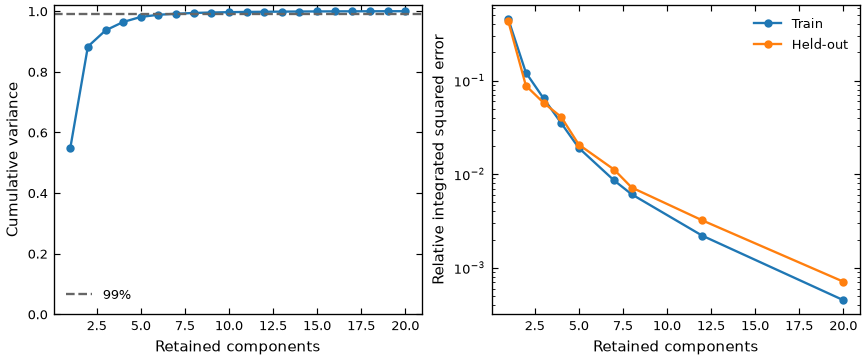

In [3]:
train_index, test_index = train_test_split(np.arange(len(fields)), test_size=0.2, random_state=SEED)
training_model = FunctionalPCA(alphas, reynolds).fit(fields[train_index])
training_rank = training_model.rank(VARIANCE_FRACTION)
ranks = sorted(set([1, 2, 3, 4, 5, 8, 12, 20, training_rank]))
reconstruction_rows = []
for split, indices in [("Train", train_index), ("Held-out", test_index)]:
    for rank in ranks:
        restored = training_model.inverse_transform(training_model.transform(fields[indices], rank))
        reconstruction_rows.append({"split": split, "rank": rank,
            **reconstruction_metrics(fields[indices], restored, training_model)})
reconstruction = pd.DataFrame(reconstruction_rows)
model, features = representations(fields, geometry, alphas, reynolds, VARIANCE_FRACTION)
scores = features["MFPCA"]
print(f"99% rank: training={training_rank}, full population={model.rank()}")
display(reconstruction[reconstruction['rank'].isin([2, training_rank])])
display(pd.DataFrame({"coefficient": ["CD", "CL"], "integrated_std": model.scale_^^}))
fig = plot_reduction(model, reconstruction)
fig.savefig(FIGURES / "reduction.pdf")
fig.savefig(FIGURES / "reduction.png")
plt.show()

## 3. Matched clustering comparison

All partitions are assessed in the **same balanced full-field metric**, including partitions fitted in geometry space. The field silhouette measures separation; relative within-cluster field SSE measures residual error around the cluster-mean surfaces (one global mean gives 1). Lower SSE means better aerodynamic compression, not necessarily more natural classes. PCA/K-means directly favors this metric, so this comparison tests the suitability of a representation for that objective, not universal superiority.

The two-parameter camber baseline is standardized `(m,p)`; full geometry adds thickness. Mean lift/drag are also standardized. Both camber baselines assign `p=0` to symmetric airfoils; a later sensitivity check removes them. GMM uses five starts, full covariance, and regularization `1e-6`; K-means uses twenty starts. Convergence and smallest cluster sizes are recorded. GMM BIC is only comparable over k **within the same fixed representation**, not between spaces of different dimension. See the official [clustering](https://scikit-learn.org/stable/modules/clustering.html) and [mixture](https://scikit-learn.org/stable/modules/mixture.html) documentation.

,representation,method,k,dimensions,converged,bic,mean_max_probability,field_silhouette,relative_field_sse,CD_rmse,CL_rmse,min_cluster_size,max_cluster_size,actual_k,ARI_vs_camber
2,MFPCA,K-means,4,7,True,NaN,NaN,0.4619,0.2612,0.0116,0.1461,14,66,4,0.3288
107,Full fields,K-means,4,5000,True,NaN,NaN,0.4619,0.2612,0.0116,0.1461,14,66,4,0.3288
23,MFPCA-2D,K-means,4,2,True,NaN,NaN,0.4584,0.2623,0.0116,0.1468,15,66,4,0.3258
9,MFPCA,Ward,4,7,True,NaN,NaN,0.4403,0.2782,0.0110,0.1611,15,80,4,0.1250
30,MFPCA-2D,Ward,4,2,True,NaN,NaN,0.3984,0.2836,0.0118,0.1555,40,47,4,0.1228
51,Field means,Ward,4,2,True,NaN,NaN,0.3609,0.3051,0.0129,0.1533,31,52,4,0.1124
44,Field means,K-means,4,2,True,NaN,NaN,0.3602,0.3090,0.0138,0.1450,28,51,4,0.2216
16,MFPCA,GMM,4,7,True,-1655.1666,0.9840,0.3076,0.3682,0.0098,0.2073,9,84,4,0.1034
58,Field means,GMM,4,2,True,621.0635,0.8935,0.2578,0.3804,0.0128,0.1882,22,62,4,0.1293
37,MFPCA-2D,GMM,4,2,True,428.0442,0.9589,0.2418,0.4432,0.0149,0.1927,9,73,4,0.1319


Nonconverged fits: 0
Partitions with fewer groups than requested: 0


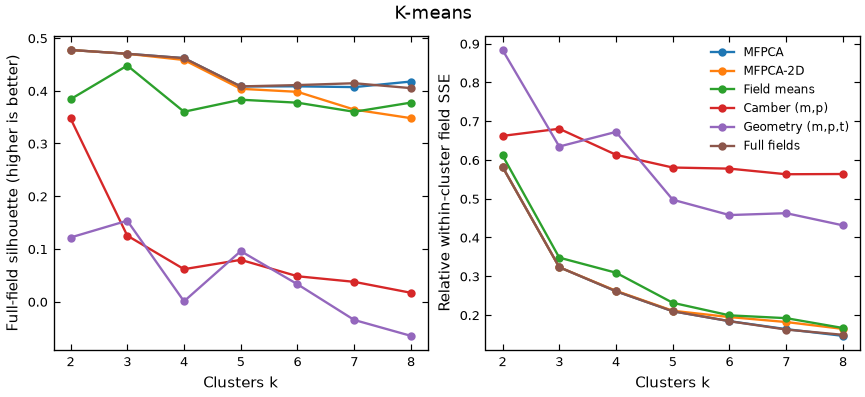

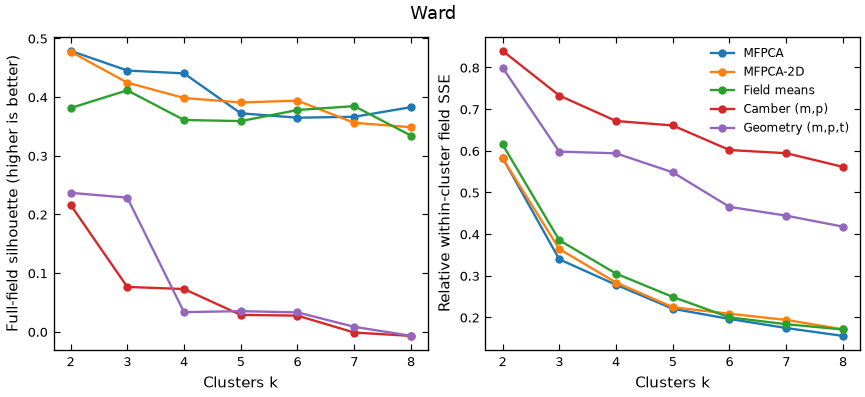

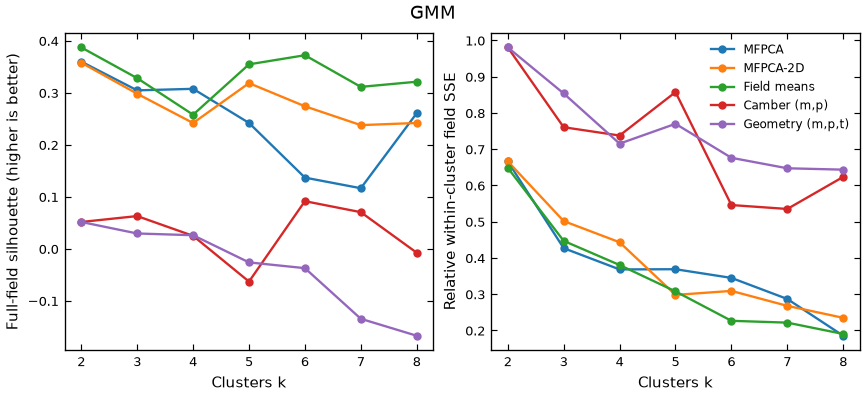

In [4]:
METHODS = ["K-means", "Ward", "GMM"]
rows, assignments = [], {}
for representation, matrix in features.items():
    for method in METHODS:
        for k in K_VALUES:
            labels, diagnostics = fit_clusters(matrix, method, k, SEED)
            assignments[(representation, method, k)] = labels
            rows.append({"representation": representation, "method": method, "k": k,
                         "dimensions": matrix.shape[1], **diagnostics, **field_metrics(fields, labels, model)})
# Unreduced baseline quantifies what PCA truncation changes.
for k in K_VALUES:
    labels, diagnostics = fit_clusters(model.weighted(fields), "K-means", k, SEED)
    assignments[("Full fields", "K-means", k)] = labels
    rows.append({"representation": "Full fields", "method": "K-means", "k": k,
                 "dimensions": model.weighted(fields).shape[1], **diagnostics, **field_metrics(fields, labels, model)})
results = pd.DataFrame(rows)
results["ARI_vs_camber"] = [adjusted_rand_score(
    assignments[(row.representation, row.method, row.k)],
    assignments[("Camber (m,p)", row.method, row.k)]) for row in results.itertuples()]
primary = results[results.k == PRIMARY_K].copy()
display(primary.sort_values("relative_field_sse").round(4))
print("Nonconverged fits:", int((~results.converged).sum()))
print("Partitions with fewer groups than requested:", int((results.actual_k != results.k).sum()))
for method in METHODS:
    fig = plot_cluster_sweep(results, method)
    fig.savefig(FIGURES / f"sweep_{method.lower()}.pdf")
    fig.savefig(FIGURES / f"sweep_{method.lower()}.png")
    plt.show()

## 4. Stability under population perturbations

Ten reproducible 80% subsamples refit coefficient scales, PCA, feature standardization, and clustering. ARI compares each subsample partition with the full-data partition restricted to the same airfoils. This measures sensitivity to sampling and initialization together; it is not an independent validation set or a confidence interval. The same subsamples are used for all methods. Ward is refitted on the subset and needs no artificial out-of-sample predictor.

In [5]:
rng = np.random.default_rng(SEED)
stability_rows = []
for repeat in range(STABILITY_REPEATS):
    indices = np.sort(rng.choice(len(fields), int(0.8 * len(fields)), replace=False))
    _, subset_features = representations(fields[indices], geometry[indices], alphas, reynolds, VARIANCE_FRACTION)
    for representation, matrix in subset_features.items():
        for method in METHODS:
            labels, diagnostics = fit_clusters(matrix, method, PRIMARY_K, SEED + repeat + 1)
            stability_rows.append({"repeat": repeat, "representation": representation, "method": method,
                "ARI": adjusted_rand_score(assignments[(representation, method, PRIMARY_K)][indices], labels),
                "dimensions": matrix.shape[1], "converged": diagnostics["converged"]})
stability = pd.DataFrame(stability_rows)
stability_summary = stability.groupby(["representation", "method"]).agg(
    ARI_mean=("ARI", "mean"), ARI_std=("ARI", "std"), ARI_min=("ARI", "min"),
    converged=("converged", "all"))
display(stability_summary.round(3))

ARI_mean  ARI_std  ARI_min  converged
representation   method                                        
Camber (m,p)     GMM         0.497    0.156    0.391       True
                 K-means     0.975    0.081    0.745       True
                 Ward        0.247    0.120    0.147       True
Field means      GMM         0.756    0.125    0.544       True
                 K-means     0.908    0.161    0.459       True
                 Ward        0.786    0.150    0.616       True
Geometry (m,p,t) GMM         0.414    0.238    0.133       True
                 K-means     0.639    0.191    0.422       True
                 Ward        0.407    0.140    0.186       True
MFPCA            GMM         0.581    0.085    0.421       True
                 K-means     0.889    0.155    0.459       True
                 Ward        0.637    0.175    0.440       True
MFPCA-2D         GMM         0.723    0.170    0.451       True
                 K-means     0.706    0.234    0.472       True
                 Ward        0.844    0.121    0.594       True

## 5. Sensitivity to representation assumptions

At fixed $k=4$, compare 95%, 99%, and 99.9% variance retention, unbalanced coefficients ($s_j=1$), and every-other-point subsampling **including both domain endpoints**. The latter is a quadrature/coarsening diagnostic on the same generated fields, not a higher-resolution solver convergence study. Refit PCA for each case and evaluate labels in the original full-field metric. We also remove symmetric airfoils to check the artificial $p=0$ convention; those metrics use the restricted population with the reference metric's scales. ARI is always against the original MFPCA partition restricted to the same observations.

In [6]:
sensitivity_rows = []
variants = {}
for fraction in [0.95, 0.99, 0.999]:
    variants[f"balanced-{fraction}"] = (np.arange(len(fields)), model.transform(fields, model.rank(fraction)))
unbalanced = FunctionalPCA(alphas, reynolds, balance=False).fit(fields)
variants["unbalanced-0.99"] = (np.arange(len(fields)), unbalanced.transform(fields, unbalanced.rank()))
ai = np.unique(np.r_[np.arange(0, len(alphas), 2), len(alphas)-1])
ri = np.unique(np.r_[np.arange(0, len(reynolds), 2), len(reynolds)-1])
coarse_fields = fields[:, ai][:, :, ri]
coarse_model = FunctionalPCA(alphas[ai], reynolds[ri]).fit(coarse_fields)
variants["coarse-grid-0.99"] = (np.arange(len(fields)), coarse_model.transform(coarse_fields, coarse_model.rank()))
cambered = np.flatnonzero(geometry[:, 0] > 0)
_, cambered_features = representations(fields[cambered], geometry[cambered], alphas, reynolds)
for name in ["MFPCA", "Camber (m,p)", "Geometry (m,p,t)"]:
    variants[f"no-symmetric/{name}"] = (cambered, cambered_features[name])
for variant, (indices, matrix) in variants.items():
    for method in METHODS:
        labels, diagnostics = fit_clusters(matrix, method, PRIMARY_K, SEED)
        sensitivity_rows.append({"variant": variant, "method": method, "dimensions": matrix.shape[1],
            "ARI_vs_primary_MFPCA": adjusted_rand_score(assignments[("MFPCA", method, PRIMARY_K)][indices], labels),
            **diagnostics, **field_metrics(fields[indices], labels, model)})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))

,variant,method,dimensions,ARI_vs_primary_MFPCA,converged,bic,mean_max_probability,field_silhouette,relative_field_sse,CD_rmse,CL_rmse,min_cluster_size,max_cluster_size,actual_k
0,balanced-0.95,K-means,4,0.9529,True,NaN,NaN,0.4623,0.2613,0.0113,0.1496,14,67,4
1,balanced-0.95,Ward,4,0.5612,True,NaN,NaN,0.3871,0.2844,0.0117,0.1564,40,47,4
2,balanced-0.95,GMM,4,0.4012,True,-216.7838,0.9710,0.3003,0.3837,0.0109,0.2059,28,63,4
3,balanced-0.99,K-means,7,1.0000,True,NaN,NaN,0.4619,0.2612,0.0116,0.1461,14,66,4
4,balanced-0.99,Ward,7,1.0000,True,NaN,NaN,0.4403,0.2782,0.0110,0.1611,15,80,4
5,balanced-0.99,GMM,7,1.0000,True,-1655.1666,0.9840,0.3076,0.3682,0.0098,0.2073,9,84,4
6,balanced-0.999,K-means,16,1.0000,True,NaN,NaN,0.4619,0.2612,0.0116,0.1461,14,66,4
7,balanced-0.999,Ward,16,0.7603,True,NaN,NaN,0.4615,0.2628,0.0110,0.1530,15,67,4
8,balanced-0.999,GMM,16,0.6757,True,-9741.0215,0.9999,0.3866,0.3185,0.0100,0.1868,9,73,4
9,unbalanced-0.99,K-means,4,0.2720,True,NaN,NaN,0.2273,0.5560,0.0228,0.1138,10,63,4


## 6. Interpreting partitions in geometry and operating space

The primary maps show MFPCA K-means, Ward, GMM, and camber K-means on the **same two-PC projection**. Fits use all retained scores. Colors are local cluster IDs, not matched classes across methods. In camber space, deterministic horizontal offsets expose all ten thicknesses at each camber/position pair: thickness increases from left to right, with offsets from −0.54 to +0.54 percentage points. These are display offsets, not different camber values. Cluster colors match the polar plots within the MFPCA K-means partition.

Cluster-mean surfaces use shared color limits per coefficient. Reynolds-averaged polar bands show the 10th–90th percentiles across member airfoils, not model uncertainty. The table identifies the actual member closest to each functional cluster mean as a representative and gives the full geometry ranges. Clusters may follow continuous geometric gradients rather than separate populations.

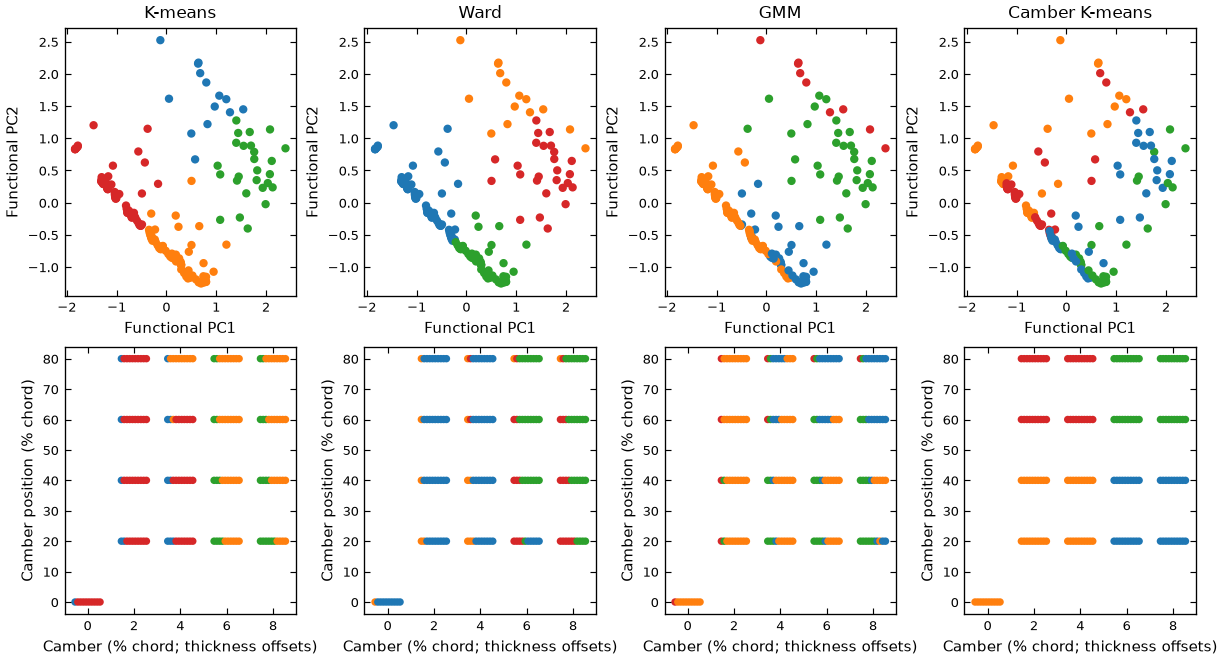

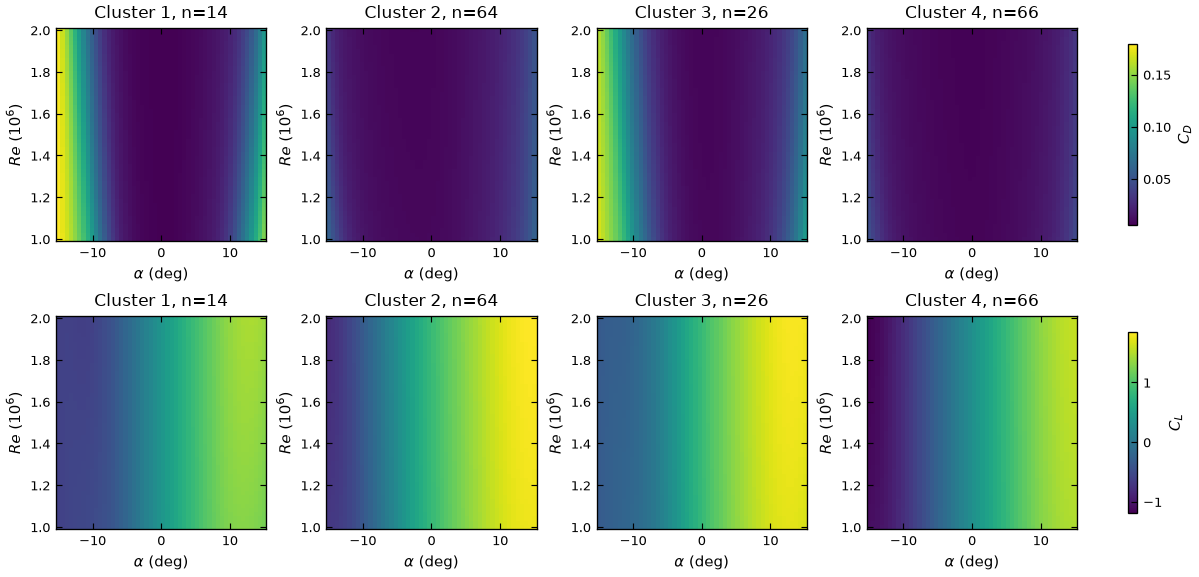

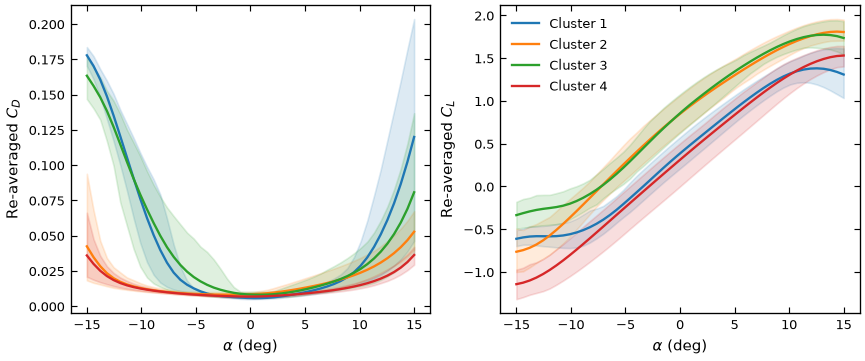

,cluster,n,representative,camber_min,camber_max,position_min,position_max,thickness_min,thickness_max
0,1,14,NACA2406,0.00,0.04,0.0,0.8,0.06,0.10
1,2,64,NACA6612,0.04,0.08,0.2,0.8,0.08,0.24
2,3,26,NACA8408,0.06,0.08,0.2,0.8,0.06,0.16
3,4,66,NACA2610,0.00,0.04,0.0,0.8,0.08,0.24


,K-means,Ward,GMM,Camber K-means
K-means,1.000,0.713,0.500,0.329
Ward,0.713,1.000,0.551,0.344
GMM,0.500,0.551,1.000,0.177
Camber K-means,0.329,0.344,0.177,1.000


In [7]:
partitions = {method: assignments[("MFPCA", method, PRIMARY_K)] for method in METHODS}
partitions["Camber K-means"] = assignments[("Camber (m,p)", "K-means", PRIMARY_K)]
fig = plot_partition_maps(model.transform(fields, 2), geometry, partitions)
fig.savefig(FIGURES / "partition_maps.pdf")
fig.savefig(FIGURES / "partition_maps.png")
plt.show()
labels = partitions["K-means"]
centroid_fig, spread_fig = plot_cluster_fields(fields, labels, alphas, reynolds, model.weights)
for fig, name in [(centroid_fig, "cluster_surfaces"), (spread_fig, "cluster_polars")]:
    fig.savefig(FIGURES / f"{name}.pdf")
    fig.savefig(FIGURES / f"{name}.png")
plt.show()
cluster_rows = []
weighted = model.weighted(fields)
for group in np.unique(labels):
    members = np.flatnonzero(labels == group)
    distances = np.sum((weighted[members] - weighted[members].mean(axis=0))**2, axis=1)
    representative = members[np.argmin(distances)]
    row = {"cluster": int(group + 1), "n": len(members), "representative": parameters.airfoil.iloc[representative]}
    for column, name in enumerate(["camber", "position", "thickness"]):
        row[name + "_min"] = geometry[members, column].min()
        row[name + "_max"] = geometry[members, column].max()
    cluster_rows.append(row)
cluster_summary = pd.DataFrame(cluster_rows)
display(cluster_summary)
agreement_names = list(partitions)
agreement = pd.DataFrame([[adjusted_rand_score(partitions[a], partitions[b]) for b in agreement_names]
                          for a in agreement_names], index=agreement_names, columns=agreement_names)
display(agreement.round(3))

## 7. Durable results and evidence notes

The following notes are generated from this execution. They distinguish compression from clustering and expose sensitivity instead of declaring a universal winner. All comparisons are restricted to the sampled NACA family and the stated NeuralFoil operating domain. The small neural model and the absence of XFoil/CFD validation or stored NeuralFoil confidence fields limit physical interpretation, especially near the angle-domain extremes. Random held-out airfoils test interpolation within this family; they do not establish extrapolation to new geometry families. Linear PCA, three standard clustering algorithms, and finite-grid quadrature are the scope here; nonlinear embeddings and cluster-aware subspaces remain separate experiments.

In [8]:
for name, table in {"reconstruction": reconstruction, "clustering": results,
                    "stability": stability, "sensitivity": sensitivity,
                    "cluster_summary": cluster_summary}.items():
    table.to_csv(RESULTS / f"{name}.csv", index=False)
stability_summary.to_csv(RESULTS / "stability_summary.csv")
agreement.to_csv(RESULTS / "partition_agreement.csv")
assignment_table = pd.concat([parameters, pd.DataFrame({
    f"{representation}/{method}/k={k}": values
    for (representation, method, k), values in assignments.items()
})], axis=1)
assignment_table.to_csv(RESULTS / "assignments.csv", index=False)
np.savez_compressed(RESULTS / "functional_pca.npz", mean=model.mean_, scales=model.scale_,
                    weights=model.weights, components=model.components_, scores=scores,
                    explained_variance=model.explained_variance_, train_index=train_index, test_index=test_index)
run_metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(), "python": platform.python_version(),
    "versions": versions, "seed": SEED, "primary_k": PRIMARY_K, "k_values": list(K_VALUES),
    "variance_fraction": VARIANCE_FRACTION, "stability_repeats": STABILITY_REPEATS,
    "cache": cache_path.name, "cache_sha256": hashlib.sha256(cache_path.read_bytes()).hexdigest(),
    "source_sha256": {path: hashlib.sha256((ROOT / path).read_bytes()).hexdigest()
                      for path in ["utils/functional_clustering.py", "utils/generate_airfoil_database.py"]},
    "config": config,
}
(RESULTS / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2) + "\n")
held = reconstruction[(reconstruction.split == "Held-out") & (reconstruction['rank'] == training_rank)].iloc[0]
notes = ["# Multivariate functional PCA: execution evidence", "",
    f"- Population: {len(fields)} airfoils; grid: {len(alphas)} × {len(reynolds)}; cache: `{cache_path.name}`.",
    f"- Full-population 99% variance rank: {model.rank()}; two PCs retain {model.explained_variance_ratio_[:2].sum():.2%}.",
    f"- Held-out reconstruction at training-selected rank {training_rank}: relative field SSE {held.relative_field_sse:.4f}, CD RMSE {held.CD_rmse:.5f}, CL RMSE {held.CL_rmse:.5f}.",
]
for method in METHODS:
    subset = primary[primary.method == method].set_index("representation")
    functional = subset.loc["MFPCA"]
    camber = subset.loc["Camber (m,p)"]
    geometry_row = subset.loc["Geometry (m,p,t)"]
    stability_row = stability_summary.loc[("MFPCA", method)]
    notes.append(f"- {method}, k={PRIMARY_K}: relative field SSE MFPCA={functional.relative_field_sse:.4f}, camber={camber.relative_field_sse:.4f}, full geometry={geometry_row.relative_field_sse:.4f}; functional/camber ARI={functional.ARI_vs_camber:.3f}; MFPCA subsample ARI mean={stability_row.ARI_mean:.3f}, min={stability_row.ARI_min:.3f}.")
km = primary[primary.method == "K-means"].set_index("representation")
notes.extend([
    f"- K-means representation check: 2-PC SSE={km.loc['MFPCA-2D', 'relative_field_sse']:.4f}, means SSE={km.loc['Field means', 'relative_field_sse']:.4f}, unreduced fields SSE={km.loc['Full fields', 'relative_field_sse']:.4f}. Two PCs perform nearly as well for this partition despite retaining only 88% of variance; richer scores matter more for reconstruction.",
])
for variant in ["balanced-0.95", "balanced-0.999", "unbalanced-0.99", "coarse-grid-0.99"]:
    rows_for_variant = sensitivity[sensitivity.variant == variant]
    values = ", ".join(f"{row.method}={row.ARI_vs_primary_MFPCA:.3f}" for row in rows_for_variant.itertuples())
    notes.append(f"- Sensitivity ARI versus primary partition, {variant}: {values}.")
notes.extend([
    f"- Nonconverged fits: main={int((~results.converged).sum())}, subsampling={int((~stability.converged).sum())}, sensitivity={int((~sensitivity.converged).sum())}.",
    "- Interpretation: field SSE measures compression under the chosen balanced metric; functional clustering is designed for this metric. ARI with geometry is agreement, not ground-truth accuracy.",
    "- Limitations: no physical class labels, confidence filtering, CFD validation, or extrapolation test. Symmetric-airfoil position is a convention; consult no-symmetric sensitivity rows. Coarse-grid checks are not solver convergence.",
    "- Figure content: reduction = variance and held-out error; sweeps = matched-k common-metric comparisons; maps = local cluster colors and explicit thickness offsets in camber geometry; surfaces = cluster means with shared coefficient scales; polar bands = member 10–90% spread.",
    "- Reproduce: execute all cells of `notebooks/multivariate_pca_clustering.ipynb`; numeric inputs are reused only when the generation configuration matches. Tables and fitted PCA arrays are in `data/multivariate_pca_clustering/`; PDFs/PNGs are in `figures/multivariate_pca_clustering/`.",
])
notes_text = "\n".join(notes) + "\n"
(ROOT / "notebooks/multivariate_pca_clustering.md").write_text(notes_text)
print(notes_text)
thread_limits.restore_original_limits()

# Multivariate functional PCA: execution evidence

- Population: 170 airfoils; grid: 50 × 50; cache: `fields_f172ec2047e982df.npz`.
- Full-population 99% variance rank: 7; two PCs retain 88.29%.
- Held-out reconstruction at training-selected rank 7: relative field SSE 0.0112, CD RMSE 0.00247, CL RMSE 0.02526.
- K-means, k=4: relative field SSE MFPCA=0.2612, camber=0.6131, full geometry=0.6722; functional/camber ARI=0.329; MFPCA subsample ARI mean=0.889, min=0.459.
- Ward, k=4: relative field SSE MFPCA=0.2782, camber=0.6715, full geometry=0.5938; functional/camber ARI=0.125; MFPCA subsample ARI mean=0.637, min=0.440.
- GMM, k=4: relative field SSE MFPCA=0.3682, camber=0.7376, full geometry=0.7152; functional/camber ARI=0.103; MFPCA subsample ARI mean=0.581, min=0.421.
- K-means representation check: 2-PC SSE=0.2623, means SSE=0.3090, unreduced fields SSE=0.2612. Two PCs perform nearly as well for this partition despite retaining only 88% of variance; richer scores matter more for recons